# Open-data intake: pregnancy ML baselines

Reproducible quality companion for the source archives and prepared tables. The notebook reads the generated intake report; it does not modify source data.

## tl;dr

- CDC/NCHS prepared baseline: **7,224,951** birth records across 2023–2024.
- UCI CTG: **2,126** rows; **11** exact duplicates.
- CTU-UHB: **552** indexed CTG records.
- TPEHG: **300** indexed EHG records.
- These sources support offline baselines and pipeline validation only; they do not establish clinical utility or Russian-population transportability.

## Context & Methods

### Key Assumptions

- 2023 is the development period and 2024 is a retrospective temporal test for CDC baselines; the HDP-proxy study also reports requested pooled 2023+2024 folds. The 2024 labels have already been inspected in exploratory analyses, so the temporal test is not untouched.
- The CDC analytic population is U.S. resident births (`RESTATUS` 1/2/3); foreign residents remain only in the raw archive.
- CDC targets are birth-record proxy labels; no diagnosis timestamp is inferred.
- CTU-UHB, UCI CTG and TPEHG are evaluated independently and are never row-joined.
- Missing values remain missing; rates use the known-label denominator.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.2,
    'font.size': 10,
})
ROOT = Path.cwd()
REPORT = json.loads((ROOT / 'research/reports/open_data_intake.json').read_text())
PREVIEW_DIR = ROOT / 'tmp/notebooks'
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

## Data

### 1. Verify downloaded archives

In [2]:
archives = pd.DataFrame(REPORT['archives'])
archives['size_mib'] = archives['size_bytes'] / 1024**2
archives[['dataset_id', 'size_mib', 'source_valid', 'file_count', 'sha256']].round({'size_mib': 1})

,dataset_id,size_mib,source_valid,file_count,sha256
0,cdc_natality_2023_nber_csv,188.4,True,1,576a16bde51a9b7ebb36c9928d6605dd6eeba15e5dcd9f...
1,cdc_natality_2024_nber_csv,190.3,True,1,9f1d6575baa6381e43c2fc81d00ff8a1de9926a014d585...
2,ctu_uhb_ctgdb_1_0_0,38.0,True,1108,edd29f16747d5300dabce77ca484cb5ff8399589f2128d...
3,uci_cardiotocography_193,0.3,True,1,ba2853564e282779907242b7bd8a83265d9fc4e79bb008...
4,tpehgdb_1_0_1,245.4,True,607,d98674703ea502620bec782f86d0f6099aea2003fd4e8d...


## Results

### 2. Target prevalence by source year

In [3]:
prevalence = pd.DataFrame(REPORT['prepared']['cdc_natality']['target_prevalence'])
prevalence_table = prevalence.pivot(index='target', columns='source_year', values='prevalence')
prevalence_table

source_year,2023,2024
target,,
target_eclampsia,0.002366,0.002267
target_gdm,0.082629,0.084782
target_hdp_proxy,0.102752,0.106045
target_ptb32,0.015654,0.015359
target_ptb37,0.104053,0.104071


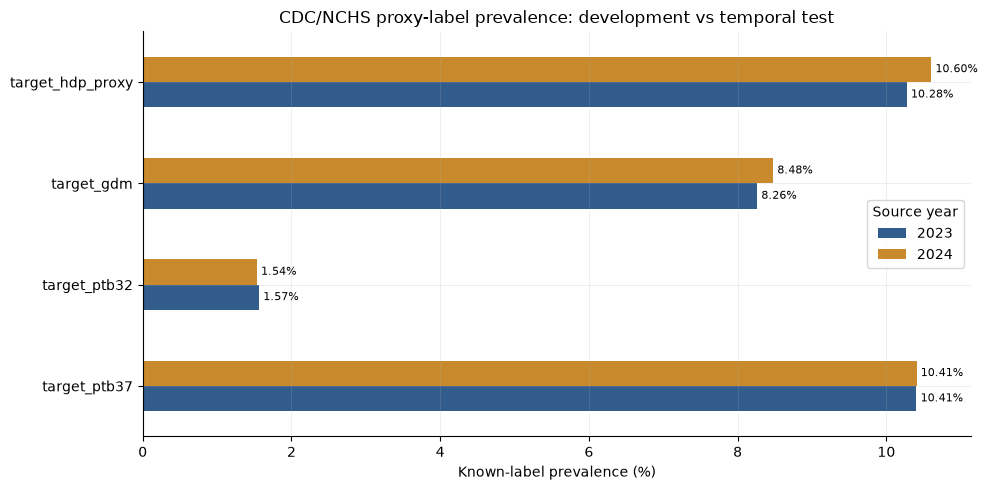

In [4]:
plot_targets = ['target_ptb37', 'target_ptb32', 'target_gdm', 'target_hdp_proxy']
plot_data = prevalence_table.loc[plot_targets] * 100
ax = plot_data.plot(kind='barh', color=['#315C8B', '#C98A2E'])
ax.set_title('CDC/NCHS proxy-label prevalence: development vs temporal test')
ax.set_xlabel('Known-label prevalence (%)')
ax.set_ylabel('')
ax.legend(title='Source year')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=8)
plt.tight_layout()
plt.savefig(PREVIEW_DIR / 'target_prevalence.png', dpi=160, bbox_inches='tight')
plt.show()

The chart compares like-for-like source fields by year. It is a drift check, not evidence that any target is predictable or clinically actionable.

### 3. Missingness in baseline predictors

In [5]:
missingness = pd.DataFrame(REPORT['prepared']['cdc_natality']['feature_missingness'])
missing_table = missingness.pivot(index='feature', columns='source_year', values='missing_rate')
missing_table

source_year,2023,2024
feature,,
bmi,0.022857,0.024347
cig_0,0.003945,0.005027
dplural,0.000000,0.000000
mager,0.000000,0.000000
meduc,0.017924,0.018988
priorlive,0.001518,0.002594
pwgt_r,0.019994,0.021249
rf_ppterm,0.001600,0.002012


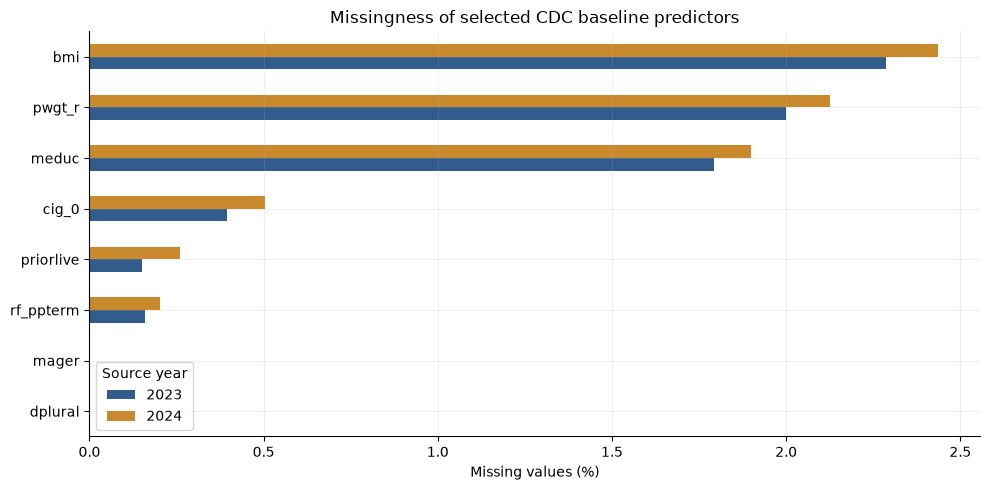

In [6]:
missing_plot = missing_table.sort_values(2024, ascending=True) * 100
ax = missing_plot.plot(kind='barh', color=['#315C8B', '#C98A2E'])
ax.set_title('Missingness of selected CDC baseline predictors')
ax.set_xlabel('Missing values (%)')
ax.set_ylabel('')
ax.legend(title='Source year')
plt.tight_layout()
plt.savefig(PREVIEW_DIR / 'feature_missingness.png', dpi=160, bbox_inches='tight')
plt.show()

### 4. Signal and feature datasets

In [7]:
summary_rows = []
for key in ['uci_cardiotocography', 'ctu_uhb_ctg', 'tpehg']:
    item = REPORT['prepared'][key]
    summary_rows.append({
        'dataset': key,
        'records': item.get('rows', item.get('records')),
        'duplicates': item.get('exact_duplicate_rows', item.get('duplicate_record_ids')),
        'missing_signal_files': item.get('missing_signal_files'),
    })
pd.DataFrame(summary_rows)

,dataset,records,duplicates,missing_signal_files
0,uci_cardiotocography,2126,11,NaN
1,ctu_uhb_ctg,552,0,0.0
2,tpehg,300,0,0.0


## Takeaways

1. CDC/NCHS provides the scale needed for simple, temporally held-out tabular baselines, but not longitudinal PE/PTB modeling.
2. CTU-UHB is the primary outcome-linked CTG benchmark; UCI CTG remains a feature/classification tutorial.
3. TPEHG is suitable for signal-pipeline R&D, with uncertainty dominated by the small preterm event count.
4. ICN and true FGR remain data-acquisition problems, not open-data ML tasks.
5. Before training, duplicates/windows must be grouped by source record and all target-specific leakage exclusions must be enforced.